In [1]:
import json
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [6]:
with open("/data/horse/ws/s4610340-isml/dev/superconduct_tc_reg.json") as fp:
    data = json.load(fp)

print(data)

[{'experiment': '001_superconduct_tc_reg_dnn_opt_split_random', 'image': '/data/horse/ws/s4610340-isml/sifs/superconduct_tc_reg_364ae87.sif', 'model': 'superconduct_tc_reg.models.dnn.DNNModel', 'dataset': 'UCIML_superconductivity_data', 'experiments_path': '/data/horse/ws/s4610340-isml/superconduct_tc_reg/experiments/001_superconduct_tc_reg_dnn_opt_split_random', 'transfer_learning': False, 'params_example': {'dir/data': '/data/horse/ws/s4610340-isml/superconduct_tc_reg/data', 'dataset/file': 'train-ho-hd_5-sc_std-cfs.csv', 'dataset/name': 'train-ho-hd_5-sc_std-cfs.csv', 'dataset/dir': '/data/horse/ws/s4610340-isml/superconduct_tc_reg/data/processed/train-ho-hd_5-sc_std-cfs.csv', 'split/_partial_': 'False', 'split/_target_': 'superconduct_tc_reg.folds_gen.TrainValRandomSplitSingleFold', 'split/val_size': '0.2', 'split/stratified': 'False', 'split/split_algorithm_seed': '6840', 'tracking/_target_': 'isml_train.tracking.LightningFileSystemLogger', 'tracking/out_path': '/data/horse/ws/s46

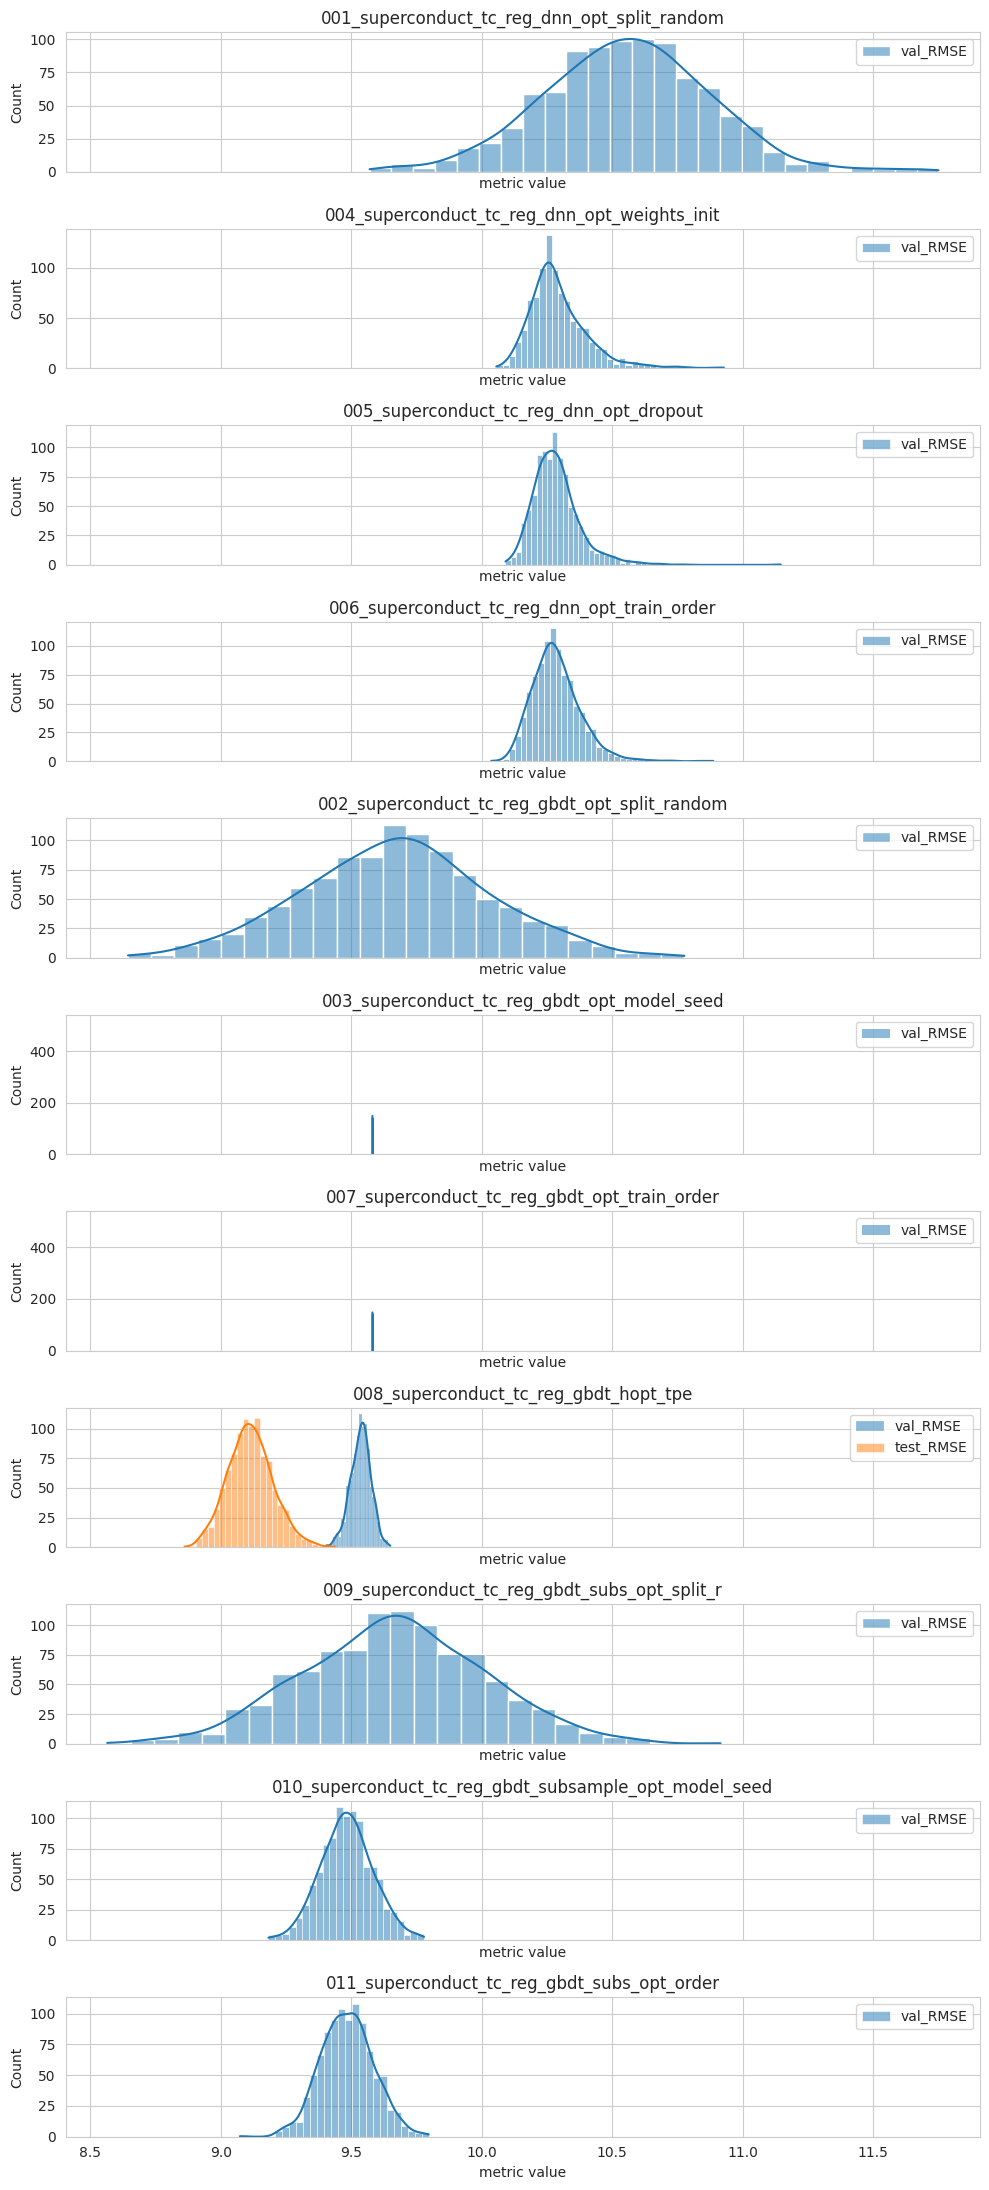

In [12]:
import numpy as np
fig, axs = plt.subplots(nrows=len(data), figsize=(10, 2*len(data)), sharex="col")

for ax, experiment_data in zip(axs, data):
    if experiment_data["model"] == "superconduct_tc_reg.models.dnn.DNNModel":
        train_m = np.sqrt(np.array(experiment_data["metric_values"]["train_loss"]))
    else:
        train_m = experiment_data["metric_values"]["train_RMSE"]
    ax.set_title(experiment_data["experiment"])
    ax.set_xlabel("metric value")
    val_m = experiment_data["metric_values"]["val_RMSE"]
    sns.histplot(x=val_m, ax=ax, kde=True, label="val_RMSE")
    #sns.histplot(x=train_m, ax=ax, kde=True, label="train_RMSE")
    if "test_RMSE" in experiment_data["metric_values"]:
        sns.histplot(x=experiment_data["metric_values"]["test_RMSE"], ax=ax, kde=True, label="test_RMSE")

    ax.legend()

fig.tight_layout()